فیلترشکن روشن کنید تا عکسها باز بشن

# ترجمه با ترنسفرمر

این پروژه نحوه ایجاد و آموزش یک مدل دنباله به دنباله به نام مدل Transformer را برای ترجمه [پرتغالی به انگلیسی] نشان می‌دهد.
منبع مجموعه داده: (https://www.tensorflow.org/datasets/catalog/ted_hrlr_translate#ted_hrlr_translatept_to_en).

ترانسفورماتورها شبکه های عصبی عمیقی هستند که CNN و RNN را با "توجه به خود" جایگزین می کنند. توجه به خود به ترانسفورماتورها اجازه می دهد به راحتی اطلاعات را در توالی های ورودی منتقل کنند.

شبکه‌های عصبی برای ترجمه ماشینی معمولاً حاوی یک رمزگذار هستند که جمله ورودی را می‌خواند و نمایشی از آن ایجاد می‌کند.
سپس یک رمز گشا، جمله خروجی را کلمه به کلمه تولید می کند و در عین حال به بازنمایی تولید شده توسط رمزگذار مشورت می کند.

Transformer با ایجاد نمایش های اولیه یا Embeddings برای هر کلمه شروع می شود. سپس، با استفاده از توجه به خود، اطلاعات را از تمام کلمات دیگر جمع‌آوری می‌کند و به ازای هر کلمه یک نمایش جدید ایجاد می‌کند که توسط کل زمینه، که توسط توپ‌های پر شده نشان داده می‌شود. سپس این مرحله چندین بار به طور موازی برای همه کلمات تکرار می شود و به طور متوالی بازنمایی های جدیدی ایجاد می کند.

<img src="https://www.tensorflow.org/images/tutorials/transformer/apply_the_transformer_to_machine_translation.gif" alt="Applying the Transformer to machine translation">

Figure 1: Applying the Transformer to machine translation. Source: [Google AI Blog](https://ai.googleblog.com/2017/08/transformer-novel-neural-network.html).


مراحل:

- داده ها را آماده کنید.
  - تعبیه های موقعیت.
  - لایه های توجه
  - رمزگذار و رمزگشا.
- ترانسفورماتور را بسازید و آموزش دهید.

ترانسفورماتور یک مدل رمزگذار - رمزگشای دنباله به دنباله است.

یک ترانسفورماتور تک لایه کمی کد بیشتری برای نوشتن نیاز دارد، اما تقریباً مشابه مدل رمزگذار-رمزگشا RNN است. تنها تفاوت این است که لایه های RNN با لایه های خود توجه جایگزین می شوند.
ما یک ترانسفورماتور 4 لایه می سازیم که بزرگتر و قدرتمندتر است، اما اساساً پیچیده تر نیست.

## RNN+ attention

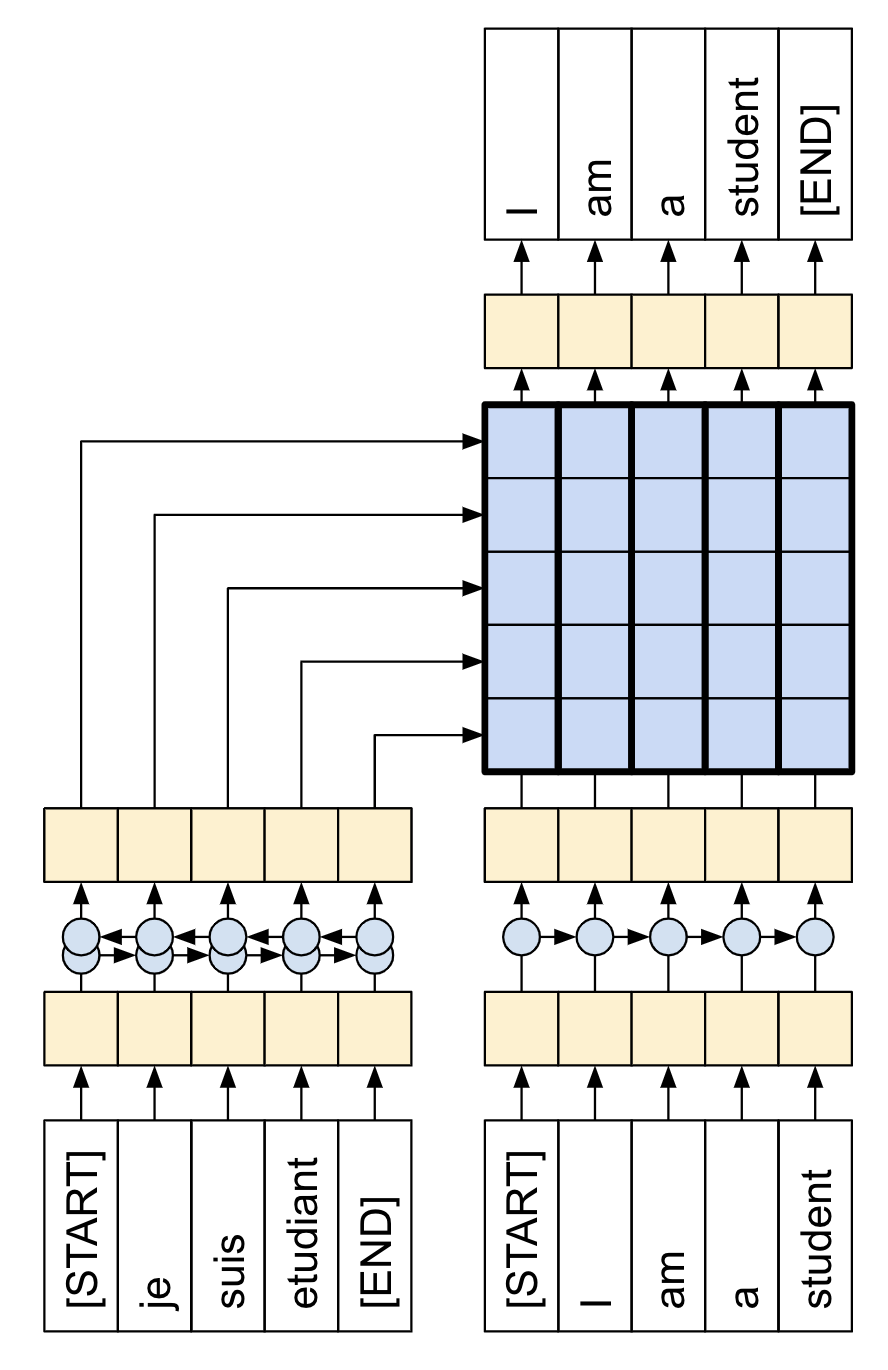

## transformer 1 layer

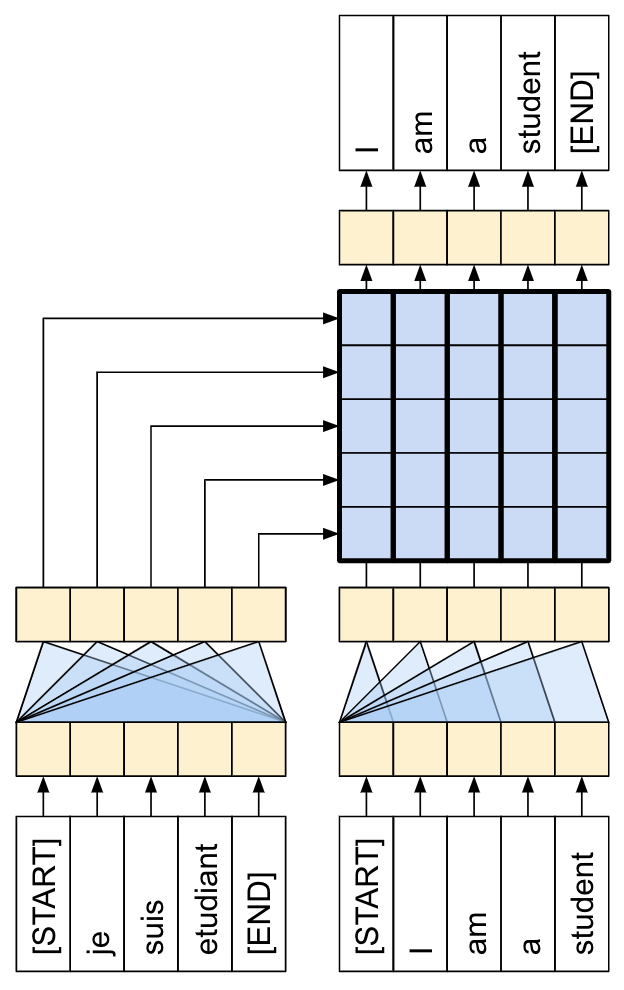

پس از آموزش مدل در این دفترچه، می توانید یک جمله پرتغالی را وارد کرده و ترجمه انگلیسی آن را برگردانید.

<img src="https://www.tensorflow.org/images/tutorials/transformer/attention_map_portuguese.png" alt="Attention heatmap">

شکل 2: وزن های توجه تولید شده که در پایان ایجاد می شوند.

## چرا ترانسفورماتورها مهم هستند

- ترانسفورماتورها در مدل سازی داده های متوالی مانند زبان طبیعی برتری دارند.
- بر خلاف شبکه های عصبی بازگشتی (RNN).
ترانسفورماتورها موازی پذیر هستند. این باعث می شود آنها در سخت افزارهایی مانند GPU و TPU کارآمد باشند. دلیل اصلی این است که ترانسفورماتورها توجه را جایگزین عود کردند و محاسبات می توانند به طور همزمان اتفاق بیفتند. خروجی های لایه را می توان به صورت موازی به جای یک سری مانند RNN محاسبه کرد.
- برخلاف RNN یا شبکه‌های عصبی کانولوشنال (CNN)، ترانسفورماتورها می‌توانند زمینه‌ها و وابستگی‌های دور یا دوربرد را در داده‌ها بین موقعیت‌های دور در توالی‌های ورودی یا خروجی ثبت کنند. بنابراین، ارتباطات طولانی تری را می توان آموخت. توجه به هر مکان اجازه می دهد تا به کل ورودی در هر لایه دسترسی داشته باشد، در حالی که در RNN و CNN، اطلاعات باید از مراحل پردازش زیادی عبور کند تا مسافت طولانی را جابجا کند، که یادگیری آن را دشوارتر می کند.
- ترانسفورماتورها هیچ فرضی در مورد روابط زمانی/مکانی بین داده ها ندارند. این برای پردازش مجموعه ای از اشیاء ایده آل است.
<img src="https://www.tensorflow.org/images/tutorials/transformer/encoder_self_attention_distribution.png" width="800" alt="توزیع خود توجه رمزگذار برای کلمه it از لایه 5 تا 6 یک ترانسفورماتور آموزش دیده بر روی ترجمه انگلیسی به فرانسوی">

شکل 3: توزیع خود توجه رمزگذار برای کلمه "it" از لایه 5 تا 6 ترانسفورماتور آموزش دیده بر روی ترجمه انگلیسی به فرانسوی (یکی از هشت سر توجه).

## کتابخانه ها

با نصب [TensorFlow Datasets] (https://tensorflow.org/datasets) برای بارگیری مجموعه داده و [TensorFlow Text] (https://www.tensorflow.org/text) برای پیش پردازش متن شروع میکنیم:

In [ ]:
# Install the most re version of TensorFlow to use the improved
# masking support for `tf.keras.layers.MultiHeadAttention`.
!apt install --allow-change-held-packages libcudnn8=8.1.0.77-1+cuda11.2
!pip uninstall -y -q tensorflow keras tensorflow-estimator tensorflow-text
!pip install -q tensorflow_datasets
!pip install -q -U tensorflow-text tensorflow

In [ ]:
import logging
import time

import numpy as np
import matplotlib.pyplot as plt

import tensorflow_datasets as tfds
import tensorflow as tf

import tensorflow_text

## Data handling

این بخش مجموعه داده و توکنایزر Subword را از [این آموزش] (https://www.tensorflow.org/text/guide/subwords_tokenizer) دانلود می‌کند، سپس همه آن‌ها را برای آموزش در «tf.data.Dataset» جمع‌بندی می‌کند.
 <section class="expandable tfo-display-only-on-site">
 <button type="button" class="button-red button expand-control">Toggle section</button>


### Download the dataset

از مجموعه داده های TensorFlow برای بارگیری [مجموعه داده ترجمه پرتغالی-انگلیسی] (https://www.tensorflow.org/datasets/catalog/ted_hrlr_translate#ted_hrlr_translatept_to_en) D Talks Open Translation Project استفاده کردم. این مجموعه داده شامل تقریباً 52000 آموزش، 1200 ولیدیشن و 1800 نمونه تست است.

In [ ]:
examples, metadata = tfds.load('ted_hrlr_translate/pt_to_en',
                               with_info=True,
                               as_supervised=True)

train_examples, val_examples = examples['train'], examples['validation']

ابجکت «tf.data.Dataset» که توسط TensorFlow Datasets برگردانده شده است، جفت نمونه متنی را به دست می دهد:

In [ ]:
for pt_examples, en_examples in train_examples.batch(3).take(1):
  print('> Examples in Portuguese:')
  for pt in pt_examples.numpy():
    print(pt.decode('utf-8'))
  print()

  print('> Examples in English:')
  for en in en_examples.numpy():
    print(en.decode('utf-8'))

### Set up the tokenizer

اکنون که مجموعه داده را بارگذاری کرده اید، باید متن را نشانه گذاری کنید، به طوری که هر عنصر به عنوان یک [token] یا Token Id (نمایش عددی) نشان داده شود.

توکن‌سازی فرآیند شکستن متن به «توکن‌ها» است. بسته به توکن ساز، این نشانه ها می توانند قطعات جمله، کلمات، زیرکلمه ها یا کاراکترها را نشان دهند.

ما از پیاده‌سازی توکنایزر زیرکلمه محبوب (https://www.tensorflow.org/text/guide/subwords_tokenizer) استفاده می‌کنیم که توکن سازهای زیرکلمه ("text.BertTokenizer") را بهینه‌سازی شده برای مجموعه داده می‌سازد و یک خروجی از آنها در یک TensorFlow ایجاد می‌کند. فرمت saved_model`.

"Saved_model" را دانلود، استخراج و وارد کنید:

In [ ]:
model_name = 'ted_hrlr_translate_pt_en_converter'
tf.keras.utils.get_file(
    f'{model_name}.zip',
    f'https://storage.googleapis.com/download.tensorflow.org/models/{model_name}.zip',
    cache_dir='.', cache_subdir='', extract=True
)

In [ ]:
tokenizers = tf.saved_model.load(model_name)

The `tf.saved_model` contains two text tokenizers, one for English and one for Portuguese. Both have the same methods:

In [ ]:
[item for item in dir(tokenizers.en) if not item.startswith('_')]

روش «tokenize»، دسته‌ای از رشته‌ها را به دسته‌ای از Token ID تبدیل می‌کند. این روش نشانه‌های نقطه‌گذاری را تقسیم می‌کند، حروف کوچک و یونیکد را عادی می‌کند قبل از توکن کردن. این استانداردسازی در اینجا قابل مشاهده نیست زیرا داده های ورودی قبلاً استاندارد شده اند.

In [ ]:
print('> This is a batch of strings:')
for en in en_examples.numpy():
  print(en.decode('utf-8'))

In [ ]:
encoded = tokenizers.en.tokenize(en_examples)

print('> This is a padded-batch of token IDs:')
for row in encoded.to_list():
  print(row)

روش "detokenize" تلاش می کند تا این شناسه های نشانه را به متن قابل خواندن توسط انسان تبدیل کند:

In [ ]:
round_trip = tokenizers.en.detokenize(encoded)

print('> This is human-readable text:')
for line in round_trip.numpy():
  print(line.decode('utf-8'))

روش «جستجو» سطح پایین‌تر از شناسه توکن به متن نشانه تبدیل می‌شود:

In [ ]:
print('> This is the text split into tokens:')
tokens = tokenizers.en.lookup(encoded)
tokens

خروجی، جنبه "subword" از "Subword Tokenization" را نشان می دهد.

For example, the word `'searchability'` is decomposed into `'search'` and `'##ability'`, and the word `'serendipity'` into `'s'`, `'##ere'`, `'##nd'`, `'##ip'` and `'##ity'`.

توجه داشته باشید که متن نشانه‌گذاری‌شده شامل نشانه‌های «[START]» و «[END]» است.

توزیع نشانه ها در هر نمونه در مجموعه داده به شرح زیر است:

In [ ]:
lengths = []

for pt_examples, en_examples in train_examples.batch(1024):
  pt_tokens = tokenizers.pt.tokenize(pt_examples)
  lengths.append(pt_tokens.row_lengths())
  
  en_tokens = tokenizers.en.tokenize(en_examples)
  lengths.append(en_tokens.row_lengths())
  print('.', end='', flush=True)

In [ ]:
all_lengths = np.concatenate(lengths)

plt.hist(all_lengths, np.linspace(0, 500, 101))
plt.ylim(plt.ylim())
max_length = max(all_lengths)
plt.plot([max_length, max_length], plt.ylim())
plt.title(f'Maximum tokens per example: {max_length}');

### Set up a data pipeline with `tf.data`

تابع زیر دسته هایی از متن را به عنوان ورودی می گیرد و آنها را به فرمتی مناسب برای آموزش تبدیل می کند.

1. آنها را به دسته های پاره پاره تبدیل می کند.
2. هرکدام از «MAX_TOKENS» بیشتر نباشد.
3. توکن های هدف (انگلیسی) را به ورودی ها و برچسب ها تقسیم می کند. اینها با یک مرحله جابجا می شوند به طوری که در هر مکان ورودی "برچسب" "ID" نشانه بعدی باشد.
4. "RaggedTensor" را به "Tensor" متراکم padded تبدیل می کند.
5. یک جفت «(ورودی‌ها، برچسب‌ها)» را برمی‌گرداند.

In [ ]:
MAX_TOKENS=128
def prepare_batch(pt, en):
    pt = tokenizers.pt.tokenize(pt)      # Output is ragged.
    pt = pt[:, :MAX_TOKENS]    # Trim to MAX_TOKENS.
    pt = pt.to_tensor()  # Convert to 0-padded dense Tensor

    en = tokenizers.en.tokenize(en)
    en = en[:, :(MAX_TOKENS+1)]
    en_inputs = en[:, :-1].to_tensor()  # Drop the [END] tokens
    en_labels = en[:, 1:].to_tensor()   # Drop the [START] tokens

    return (pt, en_inputs), en_labels

تابع زیر مجموعه داده ای از نمونه های متنی را به داده های دسته ای برای آموزش تبدیل می کند.

1. متن را نشانه می‌کند و دنباله‌های خیلی طولانی را فیلتر می‌کند.
2. متد "cache" تضمین می کند که آن CODE فقط یک بار اجرا می شود.
3. سپس «در هم ریخته» و «متراکم_تا_پاره_پاره‌ای» ترتیب را تصادفی کنید و دسته‌هایی از نمونه‌ها را جمع آوری کنید.
4. در نهایت "prefetch" مجموعه داده را به موازات مدل اجرا می کند تا اطمینان حاصل شود که داده ها در صورت نیاز در دسترس هستند.

In [ ]:
BUFFER_SIZE = 20000
BATCH_SIZE = 64

In [ ]:
def make_batches(ds):
  return (
      ds
      .shuffle(BUFFER_SIZE)
      .batch(BATCH_SIZE)
      .map(prepare_batch, tf.data.AUTOTUNE)
      .prefetch(buffer_size=tf.data.AUTOTUNE))

 </section>

## Test the Dataset 

In [ ]:
# Create training and validation set batches.
train_batches = make_batches(train_examples)
val_batches = make_batches(val_examples)

ابجکتها «tf.data.Dataset» به دست آمده برای آموزش با Keras تنظیم می شوند.
آموزش «Model.fit» Keras دارای جفت‌های «(ورودی‌ها، برچسب‌ها)» است.
"ورودی ها" جفت دنباله های پرتغالی و انگلیسی نشانه گذاری شده، "(pt, en)" هستند.
"برچسب ها" همان دنباله های انگلیسی هستند که 1 جابجا شده اند.
این تغییر به این صورت است که در هر مکان، دنباله «en»، «برچسب» در نشانه بعدی وارد می‌شود.

شکل ترنسفرمر در بالا را ببینید

این همان وظیفه تولید متن است،
به جز در اینجا شما "زمینه" ورودی اضافی دارید (توالی پرتغالی) که مدل روی آن "شرطی" شده است.

این تنظیم "اجبار معلم" نامیده می شود زیرا صرف نظر از خروجی مدل در هر مرحله زمانی، مقدار واقعی را به عنوان ورودی برای مرحله زمانی بعدی دریافت می کند.
این یک راه ساده و کارآمد برای آموزش مدل تولید متن است.
این کارآمد است زیرا نیازی به اجرای متوالی مدل ندارید، خروجی ها در مکان های توالی مختلف می توانند به صورت موازی محاسبه شوند.

ممکن است انتظار داشته باشید که جفت‌های «ورودی، خروجی» به سادگی دنباله‌های «پرتغالی، انگلیسی» باشند.
با توجه به دنباله پرتغالی، مدل سعی می کند دنباله انگلیسی را تولید کند.

آموزش یک مدل به این شکل امکان پذیر است. شما باید حلقه استنتاج را بنویسید و خروجی مدل را به ورودی برگردانید.
اما کندتر است (گام‌های زمانی نمی‌توانند به صورت موازی اجرا شوند)، و یادگیری یک کار سخت‌تر است (مدل نمی‌تواند پایان یک جمله را درست بنویسد تا زمانی که ابتدای آن درست باشد)،
اما می تواند مدل پایدارتری ارائه دهد زیرا مدل باید یاد بگیرد که در طول آموزش اشتباهات خود را اصلاح کند.

In [ ]:
for (pt, en), en_labels in train_batches.take(1):
  break

print(pt.shape)
print(en.shape)
print(en_labels.shape)

The `en` and `en_labels` are the same, just shifted by 1:

In [ ]:
print(en[0][:10])
print(en_labels[0][:10])

## Define the components

چیزهای زیادی در داخل یک ترانسفورماتور می گذرد. موارد مهمی که باید به خاطر بسپارید عبارتند از:

1. از همان الگوی کلی مانند یک مدل استاندارد توالی به دنباله با رمزگذار و رمزگشا پیروی می کند.
2. اگر قدم به قدم از طریق آن کار کنید، همه چیز منطقی خواهد بود.

ترنسفرمر 4 لایه 

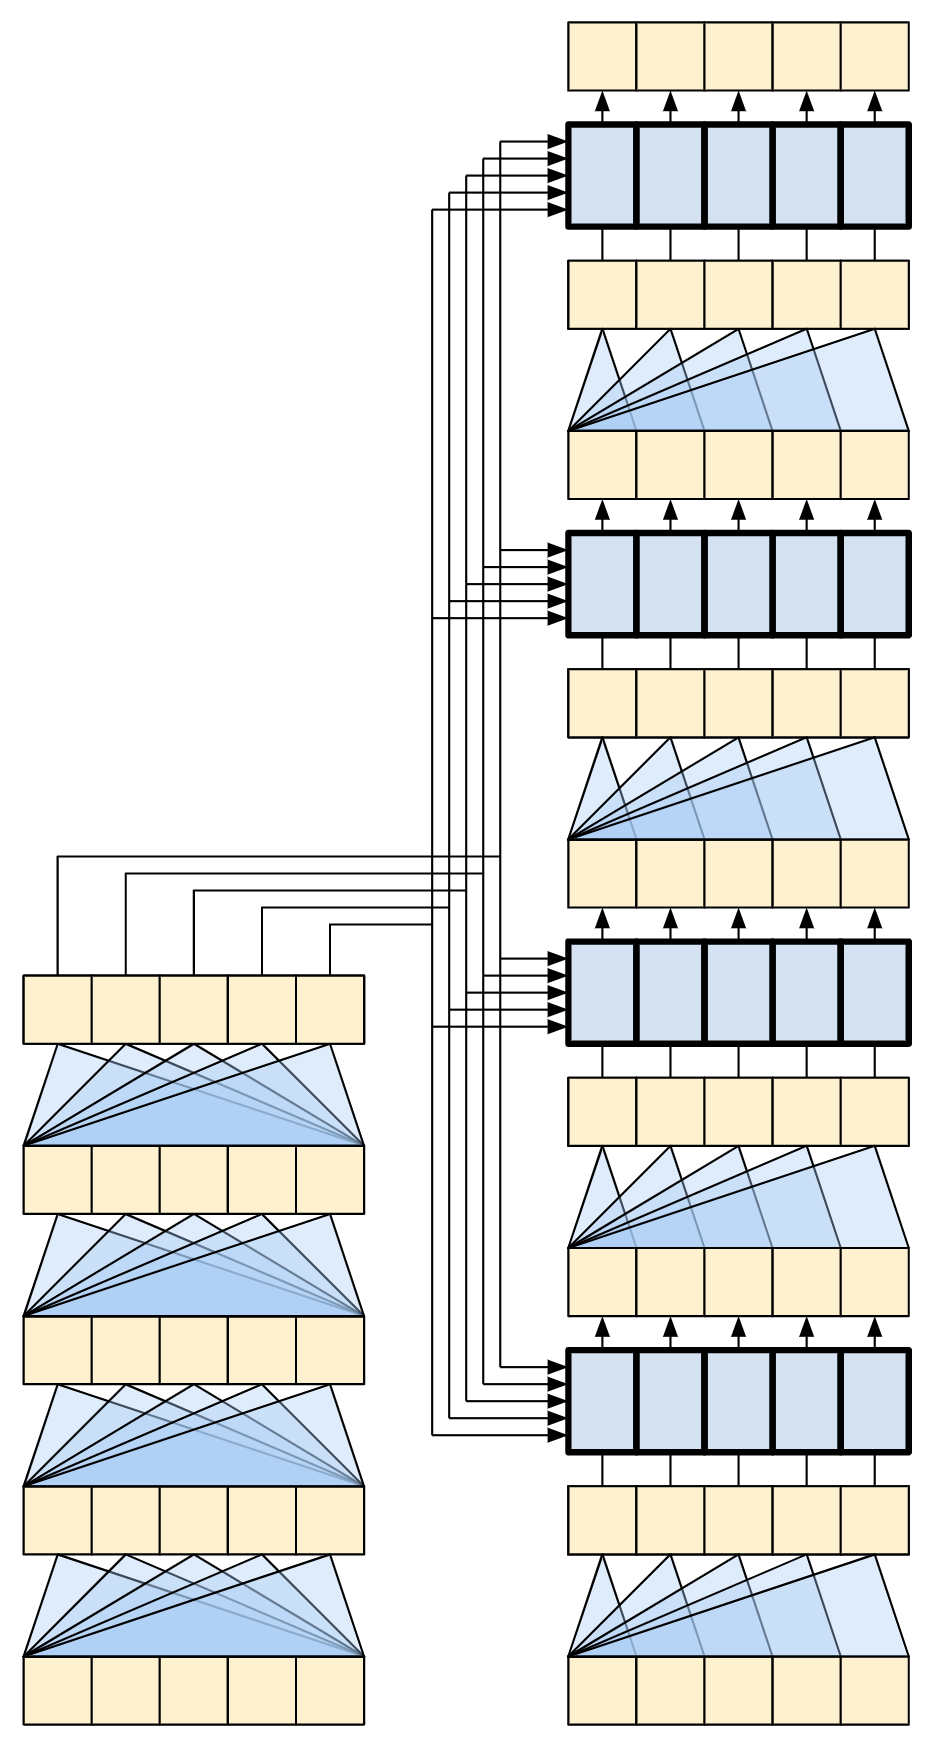

ترنسفرمر

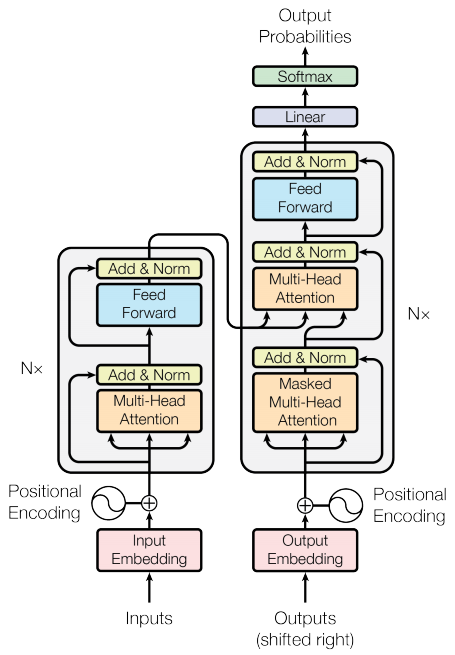

### The embedding and positional encoding layer

ورودی‌های رمزگذار و رمزگشا از منطق کدگذاری تعبیه و مکانی یکسانی استفاده می‌کنند.

<table>
<tr>
  <th colspan=1>The embedding and positional encoding layer</th>
<tr>
<tr>
  <td>
   <img src="https://www.tensorflow.org/images/tutorials/transformer/PositionalEmbedding.png"/>
  </td>
</tr>
</table>

با توجه به دنباله ای از نشانه ها، هر دو نشانه ورودی (پرتغالی) و نشانه های هدف (انگلیسی) باید با استفاده از لایه «tf.keras.layers.Embedding» به بردار تبدیل شوند.

لایه های توجه مورد استفاده در سراسر مدل ورودی خود را به عنوان مجموعه ای از بردارها، بدون ترتیب می بینند. از آنجایی که مدل حاوی هیچ لایه بازگشتی یا کانولوشنی نیست. به روشی برای شناسایی ترتیب کلمات نیاز دارد، در غیر این صورت دنباله ورودی را به عنوان یک [کیف کلمات] می بیند.
به عنوان مثال، «حالت چطوره»، «چطوری»، «تو چطوری» و غیره قابل تشخیص نیستند.

یک ترانسفورماتور یک "رمزگذاری موقعیت" را به بردارهای تعبیه شده اضافه می کند. از مجموعه ای از سینوس ها و کسینوس ها در فرکانس های مختلف (در سراسر دنباله) استفاده می کند. طبق تعریف عناصر مجاور کدگذاری موقعیت مشابهی خواهند داشت.

فرمول محاسبه کدگذاری موقعیتی (که در پایتون در زیر پیاده سازی شده است) به شرح زیر است:

$$\Large{PE_{(pos, 2i)} = \sin(pos / 10000^{2i / d_{model}})} $$
$$\Large{PE_{(pos, 2i+1)} = \cos(pos / 10000^{2i / d_{model}})} $$

In [ ]:
def positional_encoding(length, depth):
  depth = depth/2

  positions = np.arange(length)[:, np.newaxis]     # (seq, 1)
  depths = np.arange(depth)[np.newaxis, :]/depth   # (1, depth)
  
  angle_rates = 1 / (10000**depths)         # (1, depth)
  angle_rads = positions * angle_rates      # (pos, depth)

  pos_encoding = np.concatenate(
      [np.sin(angle_rads), np.cos(angle_rads)],
      axis=-1) 

  return tf.cast(pos_encoding, dtype=tf.float32)

تابع رمزگذاری موقعیت مجموعه ای از سینوس ها و کسینوس ها است که بسته به موقعیت آنها در امتداد عمق بردار تعبیه شده، در فرکانس های مختلف ارتعاش می کنند. آنها در سراسر محور موقعیت ارتعاش می کنند.

In [ ]:
pos_encoding = positional_encoding(length=2048, depth=512)

# Check the shape.
print(pos_encoding.shape)

# Plot the dimensions.
plt.pcolormesh(pos_encoding.numpy().T, cmap='RdBu')
plt.ylabel('Depth')
plt.xlabel('Position')
plt.colorbar()
plt.show()

طبق تعریف، این بردارها به خوبی با بردارهای نزدیک در امتداد محور موقعیت همسو می شوند. بردارهای کدکننده موقعیت در زیر نرمال می شوند و بردار از موقعیت '1000'، با حاصل ضرب نقطه ای، با همه موارد دیگر مقایسه می شود:

In [ ]:
pos_encoding/=tf.norm(pos_encoding, axis=1, keepdims=True)
p = pos_encoding[1000]
dots = tf.einsum('pd,d -> p', pos_encoding, p)
plt.subplot(2,1,1)
plt.plot(dots)
plt.ylim([0,1])
plt.plot([950, 950, float('nan'), 1050, 1050],
         [0,1,float('nan'),0,1], color='k', label='Zoom')
plt.legend()
plt.subplot(2,1,2)
plt.plot(dots)
plt.xlim([950, 1050])
plt.ylim([0,1])


بنابراین از این برای ایجاد یک لایه «PositionEmbedding» استفاده کنید که بردار جاسازی یک نشانه را مشاهده می کند و بردار موقعیت را اضافه می کند:

In [ ]:
class PositionalEmbedding(tf.keras.layers.Layer):
  def __init__(self, vocab_size, d_model):
    super().__init__()
    self.d_model = d_model
    self.embedding = tf.keras.layers.Embedding(vocab_size, d_model, mask_zero=True) 
    self.pos_encoding = positional_encoding(length=2048, depth=d_model)

  def compute_mask(self, *args, **kwargs):
    return self.embedding.compute_mask(*args, **kwargs)

  def call(self, x):
    length = tf.shape(x)[1]
    x = self.embedding(x)
    # This factor sets the relative scale of the embedding and positonal_encoding.
    x *= tf.math.sqrt(tf.cast(self.d_model, tf.float32))
    x = x + self.pos_encoding[tf.newaxis, :length, :]
    return x


In [ ]:
embed_pt = PositionalEmbedding(vocab_size=tokenizers.pt.get_vocab_size(), d_model=512)
embed_en = PositionalEmbedding(vocab_size=tokenizers.en.get_vocab_size(), d_model=512)

pt_emb = embed_pt(pt)
en_emb = embed_en(en)

In [ ]:
en_emb._keras_mask

این بلوک های Add & Norm در سراسر مدل پراکنده هستند. هر یک به یک اتصال باقیمانده می پیوندد و نتیجه را از طریق یک لایه «Normalization Layer» اجرا می کند.

ساده ترین راه برای سازماندهی کد در اطراف این بلوک های باقی مانده است. در بخش های زیر کلاس های لایه سفارشی برای هر کدام تعریف می شود.

بلوک های باقیمانده Add & Norm گنجانده شده اند تا آموزش کارآمد باشد. اتصال باقیمانده یک مسیر مستقیم برای گرادیان فراهم می‌کند (و تضمین می‌کند که بردارها به جای **جایگزینی*****به‌روز شده** توسط لایه‌های توجه انجام می‌شوند)، در حالی که نرمال‌سازی مقیاس معقولی را برای خروجی‌ها حفظ می‌کند.

توجه: پیاده‌سازی‌های زیر، از لایه Add استفاده می‌کنند تا اطمینان حاصل شود که ماسک‌های Keras منتشر می‌شوند (عملگر `+` این کار را نمی‌کند).

### The base attention layer



در سراسر مدل از لایه های توجه استفاده شده است. همه اینها به جز نحوه پیکربندی توجه یکسان هستند.

 Each one contains a `layers.MultiHeadAttention`, a `layers.LayerNormalization` and a `layers.Add`. 

<table>
<tr>
  <th colspan=2>The base attention layer</th>
<tr>
<tr>
  <td>
   <img src="https://www.tensorflow.org/images/tutorials/transformer/BaseAttention.png"/>
  </td>
</tr>
</table>

برای پیاده سازی این لایه های توجه، با یک کلاس پایه ساده شروع کنید که فقط شامل لایه های مؤلفه است. هر مورد استفاده به عنوان یک زیر کلاس پیاده سازی می شود. برای نوشتن به این شکل کد کمی بیشتر است، اما هدف را روشن نگه می دارد.

In [ ]:
class BaseAttention(tf.keras.layers.Layer):
  def __init__(self, **kwargs):
    super().__init__()
    self.mha = tf.keras.layers.MultiHeadAttention(**kwargs)
    self.layernorm = tf.keras.layers.LayerNormalization()
    self.add = tf.keras.layers.Add()

#### Attention refresher

قبل از اینکه به جزئیات هر کاربرد بپردازید، در اینجا یک تجدید نظر سریع در مورد نحوه عملکرد توجه آورده شده است:

<table>
<tr>
  <th colspan=1>The base attention layer</th>
</tr>
<tr>
  <td>
   <img width=430 src="https://www.tensorflow.org/images/tutorials/transformer/BaseAttention-new.png"/>
  </td>
</tr>
</table>

دو ورودی وجود دارد:

1. دنباله Query; توالی در حال پردازش؛ دنباله انجام حضور (پایین).
2. دنباله «زمینه». دنباله ای که به آن توجه می شود (سمت چپ).

خروجی همان شکل query-sequence را دارد.

مقایسه رایج این است که این عملیات مانند جستجوی فرهنگ لغت است.
جستجوی فرهنگ لغت **فازی**، **متمایز**، **بردار شده**.

در اینجا یک فرهنگ لغت معمولی پایتون وجود دارد، با 3 کلید و 3 مقدار که در یک پرس و جو ارسال می شود.

```
d = {'color': 'blue', 'age': 22, 'type': 'pickup'}
result = d['color']
```
- "Query" همان چیزی است که شما در تلاش برای پیدا کردن آن هستید.
- «Key» نوع اطلاعاتی است که فرهنگ لغت دارد.
- "VAlue" همان اطلاعات است.

وقتی یک «Query» را در یک فرهنگ لغت معمولی جستجو می‌کنید، فرهنگ لغت «KEy» ​​منطبق را پیدا می‌کند و «VAlue» مرتبط آن را برمی‌گرداند.
"Query" یا دارای "Key" منطبق است یا ندارد.
شما می توانید یک دیکشنری **فازی** را تصور کنید که در آن کلیدها لازم نیست کاملاً مطابقت داشته باشند.
اگر "d["species"]" را در فرهنگ لغت بالا جستجو کردید، شاید بخواهید "" Pickup" را برگرداند زیرا بهترین تطابق برای پرس و جو است.

یک لایه توجه یک جستجوی فازی مانند این انجام می دهد، اما فقط به دنبال بهترین کلید نیست.
«ارزش‌ها» را بر اساس میزان مطابقت «Query» با هر «کلید» ترکیب می‌کند.

چطور کار میکند؟ در یک لایه توجه، «Query»، «KEy» ​​و «VAlue» هر یک بردار هستند.
به جای انجام یک جستجوی هش، لایه توجه بردارهای «Query» و «KEy» ​​را با هم ترکیب می‌کند تا تعیین کند که چقدر با «امتیاز توجه» مطابقت دارند.
این لایه میانگین را در تمام «ارزش‌ها» که با «امتیازات توجه» وزن می‌شوند، برمی‌گرداند.

هر مکانی که query-sequence بردار «Query» ارائه می‌کند.
دنباله زمینه به عنوان فرهنگ لغت عمل می کند. در هر مکان در دنباله زمینه، بردار «KEy» ​​و «VAlue» ارائه می‌شود.
بردارهای ورودی مستقیماً استفاده نمی‌شوند، لایه «layers.MultiHeadAttention» شامل لایه‌های «LAyers.Dense» است تا بردارهای ورودی را قبل از استفاده از آن‌ها نمایش دهد.


### The cross attention layer

در مرکز تحت اللفظی ترانسفورماتور، لایه CRoss-ATtention قرار دارد. این لایه رمزگذار و رمزگشا را به هم متصل می کند. این لایه مستقیم ترین استفاده از توجه در مدل است.

<table>
<tr>
  <th colspan=1>The cross attention layer</th>
<tr>
<tr>
  <td>
   <img src="https://www.tensorflow.org/images/tutorials/transformer/CrossAttention.png"/>
  </td>
</tr>
</table>

برای پیاده سازی این، هنگام فراخوانی لایه MULTI HEAD ATTENTION دنباله هدف "x" را به عنوان "Query" و دنباله "Context" را به عنوان "Key/value" ارسال می کنید:

In [ ]:
class CrossAttention(BaseAttention):
  def call(self, x, context):
    attn_output, attn_scores = self.mha(
        query=x,
        key=context,
        value=context,
        return_attention_scores=True)
   
    # Cache the attention scores for plotting later.
    self.last_attn_scores = attn_scores

    x = self.add([x, attn_output])
    x = self.layernorm(x)

    return x

کاریکاتور زیر نشان می دهد که چگونه اطلاعات در این لایه جریان می یابد. ستون ها مجموع وزنی را در توالی زمینه نشان می دهند.

برای سادگی، اتصالات باقیمانده نشان داده نشده است.

<table>
<tr>
  <th>The cross attention layer</th>
</tr>
<tr>
  <td>
   <img width=430 src="https://www.tensorflow.org/images/tutorials/transformer/CrossAttention-new-full.png"/>
  </td>
</tr>
</table>

طول خروجی طول دنباله «Query» است، اما نه در طول توالی «KEy/value» زمینه.

نمودار در زیر ساده تر شده است. نیازی به ترسیم کل ماتریس "وزن توجه" نیست.
نکته این است که هر مکان «Query» می‌تواند تمام جفت‌های «Key/value» را در زمینه ببیند، اما هیچ اطلاعاتی بین پرس‌و‌جوها رد و بدل نمی‌شود.

<table>
<tr>
  <th>Each query sees the whole context.</th>
</tr>
<tr>
  <td>
   <img width=430 src="https://www.tensorflow.org/images/tutorials/transformer/CrossAttention-new.png"/>
  </td>
</tr>
</table>

Test run it on sample inputs:

In [ ]:
sample_ca = CrossAttention(num_heads=2, key_dim=512)

print(pt_emb.shape)
print(en_emb.shape)
print(sample_ca(en_emb, pt_emb).shape)

### The global self attention layer

این لایه مسئول پردازش توالی زمینه و انتشار اطلاعات در طول آن است:

<table>
<tr>
  <th colspan=1>The global self attention layer</th>
<tr>
<tr>
  <td>
   <img src="https://www.tensorflow.org/images/tutorials/transformer/SelfAttention.png"/>
  </td>
</tr>
</table>

از آنجایی که در حین تولید ترجمه، توالی زمینه ثابت است، اطلاعات در هر دو جهت جریان پیدا می کند.

قبل از ترانسفورماتورها و توجه به خود، مدل ها معمولاً از RNN یا CNN برای انجام این کار استفاده می کردند:

<table>
<tr>
  <th colspan=1>Bidirectional RNNs and CNNs</th>
</tr>
<tr>
  <td>
   <img width=500 src="https://www.tensorflow.org/images/tutorials/transformer/RNN-bidirectional.png"/>
  </td>
</tr>
<tr>
  <td>
   <img width=500 src="https://www.tensorflow.org/images/tutorials/transformer/CNN.png"/>
  </td>
</tr>
</table>

RNN و CNN محدودیت های خود را دارند.

- RNN به اطلاعات اجازه می دهد تا در تمام طول توالی جریان داشته باشند، اما از مراحل پردازش زیادی برای رسیدن به آنجا عبور می کند (محدود کردن جریان گرادیان). این مراحل RNN باید به صورت متوالی اجرا شوند و بنابراین RNN کمتر قادر به استفاده از دستگاه های موازی مدرن است.
- در CNN هر مکان را می توان به صورت موازی پردازش کرد، اما فقط یک میدان دریافت محدود را فراهم می کند. فیلد گیرنده تنها به صورت خطی با تعداد لایه‌های CNN رشد می‌کند، شما باید تعدادی لایه Convolution را روی هم قرار دهید تا اطلاعات را در سراسر دنباله انتقال دهید ([Wavenet](https://arxiv.org/abs/1609.03499) با استفاده از این مشکل این مشکل را کاهش می‌دهد. پیچش های گشاد شده).

از سوی دیگر، لایه توجه جهانی به هر عنصر دنباله ای اجازه می دهد تا مستقیماً به هر عنصر توالی دیگر، تنها با چند عملیات دسترسی داشته باشد، و همه خروجی ها را می توان به صورت موازی محاسبه کرد.

برای پیاده‌سازی این لایه، فقط باید دنباله هدف، «x» را به‌عنوان آرگومان‌های «پرس و جو» و «مقدار» به لایه «mha» منتقل کنید:

In [ ]:
class GlobalSelfAttention(BaseAttention):
  def call(self, x):
    attn_output = self.mha(
        query=x,
        value=x,
        key=x)
    x = self.add([x, attn_output])
    x = self.layernorm(x)
    return x

In [ ]:
sample_gsa = GlobalSelfAttention(num_heads=2, key_dim=512)

print(pt_emb.shape)
print(sample_gsa(pt_emb).shape)

با همان سبک قبلی می توانید آن را به این شکل بکشید:

<table>
<tr>
  <th colspan=1>The global self attention layer</th>
<tr>
<tr>
  <td>
   <img width=330 src="https://www.tensorflow.org/images/tutorials/transformer/SelfAttention-new-full.png"/>
  </td>
</tr>
</table>

باز هم، اتصالات باقیمانده برای وضوح حذف شده اند.

جمع و جورتر است، و به همان اندازه دقیق است که آن را به شکل زیر بکشید:

<table>
<tr>
  <th colspan=1>The global self attention layer</th>
<tr>
<tr>
  <td>
   <img width=500 src="https://www.tensorflow.org/images/tutorials/transformer/SelfAttention-new.png"/>
  </td>
</tr>
</table>

### The causal self attention layer

این لایه برای دنباله خروجی کار مشابهی را به عنوان لایه خود توجه جهانی انجام می دهد:

<table>
<tr>
  <th colspan=1>The causal self attention layer</th>
<tr>
<tr>
  <td>
   <img src="https://www.tensorflow.org/images/tutorials/transformer/CausalSelfAttention.png"/>
  </td>
</tr>
</table>

این باید به گونه ای متفاوت از لایه توجه جهانی رمزگذار مدیریت شود.

مانند [آموزش تولید متن](https://www.tensorflow.org/text/tutorials/text_generation)، و [NMT با توجه](https://www.tensorflow.org/text/tutorials/nmt_with_attention) ، ترانسفورماتورها یک مدل "خود رگرسیون" هستند: آنها متن را یک توکن تولید می کنند و آن خروجی را به ورودی برمی گرداند. برای ایجاد این _کارآمد_، این مدل ها تضمین می کنند که خروجی هر عنصر دنباله تنها به عناصر توالی قبلی بستگی دارد. مدل ها "علت" هستند.

A single-direction RNN is causal by definition. To make a causal convolution you just need to pad the input and shift the output so that it aligns correctly (use `layers.Conv1D(padding='causal')`) .

<table>
<tr>
  <th colspan=1>Causal RNNs and CNNs</th>
</tr>
<tr>
  <td>
   <img width=500 src="https://www.tensorflow.org/images/tutorials/transformer/RNN.png"/>
  </td>
</tr>
<tr>
  <td>
   <img width=500 src="https://www.tensorflow.org/images/tutorials/transformer/CNN-causal.png"/>
  </td>
</tr>
</table>

یک مدل از دو جهت کارآمد است:

1. در آموزش، به شما این امکان را می دهد تا برای هر مکان در دنباله خروجی در حالی که مدل را فقط یک بار اجرا می کنید، تلفات را محاسبه کنید.
2. در طول استنتاج، برای هر توکن جدیدی که تولید می‌شود، فقط باید خروجی‌های آن را محاسبه کنید، خروجی‌های عناصر توالی قبلی را می‌توان مجدداً استفاده کرد.
  - برای یک RNN شما فقط به حالت RNN نیاز دارید تا محاسبات قبلی را در نظر بگیرد (به سازنده لایه RNN رجوع کنید 'return_state=True').

برای ایجاد یک لایه توجه به خود، باید هنگام محاسبه امتیازات توجه و جمع کردن «VAlue» از یک ماسک مناسب استفاده کنید.

اگر «use_causal_mask = True» را هنگام فراخوانی لایه «MultiHeadAttention» به طور خودکار به آن رسیدگی می شود:

In [ ]:
class CausalSelfAttention(BaseAttention):
  def call(self, x):
    attn_output = self.mha(
        query=x,
        value=x,
        key=x,
        use_causal_mask = True)
    x = self.add([x, attn_output])
    x = self.layernorm(x)
    return x

ماسک تضمین می‌کند که هر مکان فقط به مکان‌هایی که قبل از خود هستند دسترسی دارد:

<table>
<tr>
  <th colspan=1>The causal self attention layer</th>
<tr>
<tr>
  <td>
   <img width=330 src="https://www.tensorflow.org/images/tutorials/transformer/CausalSelfAttention-new-full.png"/>
  </td>
</tr>
</table>

باز هم، اتصالات باقیمانده برای سادگی حذف شده اند.

نمایش فشرده تر این لایه به صورت زیر خواهد بود:

<table>
</tr>
  <th colspan=1>The causal self attention layer</th>
<tr>
<tr>
  <td>
   <img width=430 src="https://www.tensorflow.org/images/tutorials/transformer/CausalSelfAttention-new.png"/>
  </td>
</tr>
</table>

Test out the layer:

In [ ]:
sample_csa = CausalSelfAttention(num_heads=2, key_dim=512)

print(en_emb.shape)
print(sample_csa(en_emb).shape)

خروجی عناصر توالی اولیه به عناصر بعدی بستگی ندارد، بنابراین مهم نیست که عناصر را قبل یا بعد از اعمال لایه برش دهید:

In [ ]:
out1 = sample_csa(embed_en(en[:, :3])) 
out2 = sample_csa(embed_en(en))[:, :3]

tf.reduce_max(abs(out1 - out2)).numpy()

توجه: هنگام استفاده از ماسک های Keras، مقادیر خروجی در مکان های نامعتبر به خوبی تعریف نشده اند. بنابراین ممکن است موارد بالا برای مناطق ماسک شده صادق نباشد.

### The feed forward network

ترانسفورماتور همچنین شامل این شبکه پیشروی نقطه‌ای در رمزگذار و رمزگشا می‌شود:

<table>
<tr>
  <th colspan=1>The feed forward network</th>
<tr>
<tr>
  <td>
   <img src="https://www.tensorflow.org/images/tutorials/transformer/FeedForward.png"/>
  </td>
</tr>
</table>

شبکه از دو لایه خطی (`tf.keras.layers.Dense`) با یک فعال سازی ReLU در بین و یک لایه حذفی تشکیل شده است. همانند لایه های توجه، کد در اینجا نیز شامل اتصال باقی مانده و عادی سازی است:

In [ ]:
class FeedForward(tf.keras.layers.Layer):
  def __init__(self, d_model, dff, dropout_rate=0.1):
    super().__init__()
    self.seq = tf.keras.Sequential([
      tf.keras.layers.Dense(dff, activation='relu'),
      tf.keras.layers.Dense(d_model),
      tf.keras.layers.Dropout(dropout_rate)
    ])
    self.add = tf.keras.layers.Add()
    self.layer_norm = tf.keras.layers.LayerNormalization()

  def call(self, x):
    x = self.add([x, self.seq(x)])
    x = self.layer_norm(x) 
    return x


لایه را تست کنید، خروجی همان شکل ورودی است:

In [ ]:
sample_ffn = FeedForward(512, 2048)

print(en_emb.shape)
print(sample_ffn(en_emb).shape)

### The encoder layer

رمزگذار شامل پشته‌ای از لایه‌های رمزگذار «N» است. جایی که هر «EncoderLayer» حاوی یک لایه «GlobalSelfAttention» و «FeedForward» است:

<table>
<tr>
  <th colspan=1>The encoder layer</th>
<tr>
<tr>
  <td>
   <img src="https://www.tensorflow.org/images/tutorials/transformer/EncoderLayer.png"/>
  </td>
</tr>
</table>

Here is the definition of the `EncoderLayer`:

In [ ]:
class EncoderLayer(tf.keras.layers.Layer):
  def __init__(self,*, d_model, num_heads, dff, dropout_rate=0.1):
    super().__init__()

    self.self_attention = GlobalSelfAttention(
        num_heads=num_heads,
        key_dim=d_model,
        dropout=dropout_rate)

    self.ffn = FeedForward(d_model, dff)

  def call(self, x):
    x = self.self_attention(x)
    x = self.ffn(x)
    return x

و با یک آزمایش سریع، خروجی همان شکل ورودی را خواهد داشت:

In [ ]:
sample_encoder_layer = EncoderLayer(d_model=512, num_heads=8, dff=2048)

print(pt_emb.shape)
print(sample_encoder_layer(pt_emb).shape)

### The encoder

Next build the encoder.

<table>
<tr>
  <th colspan=1>The encoder</th>
<tr>
<tr>
  <td>
   <img src="https://www.tensorflow.org/images/tutorials/transformer/Encoder.png"/>
  </td>
</tr>
</table>

رمزگذار شامل موارد زیر است:

- A `PositionalEmbedding` layer at the input.
- A stack of `EncoderLayer` layers.

In [ ]:
class Encoder(tf.keras.layers.Layer):
  def __init__(self, *, num_layers, d_model, num_heads,
               dff, vocab_size, dropout_rate=0.1):
    super().__init__()

    self.d_model = d_model
    self.num_layers = num_layers

    self.pos_embedding = PositionalEmbedding(
        vocab_size=vocab_size, d_model=d_model)

    self.enc_layers = [
        EncoderLayer(d_model=d_model,
                     num_heads=num_heads,
                     dff=dff,
                     dropout_rate=dropout_rate)
        for _ in range(num_layers)]
    self.dropout = tf.keras.layers.Dropout(dropout_rate)

  def call(self, x):
    # `x` is token-IDs shape: (batch, seq_len)
    x = self.pos_embedding(x)  # Shape `(batch_size, seq_len, d_model)`.
    
    # Add dropout.
    x = self.dropout(x)

    for i in range(self.num_layers):
      x = self.enc_layers[i](x)

    return x  # Shape `(batch_size, seq_len, d_model)`.

Test the encoder:

In [ ]:
# Instantiate the encoder.
sample_encoder = Encoder(num_layers=4,
                         d_model=512,
                         num_heads=8,
                         dff=2048,
                         vocab_size=8500)

sample_encoder_output = sample_encoder(pt, training=False)

# Print the shape.
print(pt.shape)
print(sample_encoder_output.shape)  # Shape `(batch_size, input_seq_len, d_model)`.

### The decoder layer

The decoder's stack is slightly more complex, with each `DecoderLayer` containing a `CausalSelfAttention`, a `CrossAttention`, and a `FeedForward` layer:  

<table>
<tr>
  <th colspan=1>The decoder layer</th>
<tr>
<tr>
  <td>
   <img src="https://www.tensorflow.org/images/tutorials/transformer/DecoderLayer.png"/>
  </td>
</tr>
</table>

In [ ]:
class DecoderLayer(tf.keras.layers.Layer):
  def __init__(self,
               *,
               d_model,
               num_heads,
               dff,
               dropout_rate=0.1):
    super(DecoderLayer, self).__init__()

    self.causal_self_attention = CausalSelfAttention(
        num_heads=num_heads,
        key_dim=d_model,
        dropout=dropout_rate)
    
    self.cross_attention = CrossAttention(
        num_heads=num_heads,
        key_dim=d_model,
        dropout=dropout_rate)

    self.ffn = FeedForward(d_model, dff)

  def call(self, x, context):
    x = self.causal_self_attention(x=x)
    x = self.cross_attention(x=x, context=context)

    # Cache the last attention scores for plotting later
    self.last_attn_scores = self.cross_attention.last_attn_scores

    x = self.ffn(x)  # Shape `(batch_size, seq_len, d_model)`.
    return x

Test the decoder layer:

In [ ]:
sample_decoder_layer = DecoderLayer(d_model=512, num_heads=8, dff=2048)

sample_decoder_layer_output = sample_decoder_layer(
    x=en_emb, context=pt_emb)

print(en_emb.shape)
print(pt_emb.shape)
print(sample_decoder_layer_output.shape)  # `(batch_size, seq_len, d_model)`

### The decoder

Similar to the `Encoder`, the `Decoder` consists of a `PositionalEmbedding`, and a stack of `DecoderLayer`s:

<table>
<tr>
  <th colspan=1>The embedding and positional encoding layer</th>
<tr>
<tr>
  <td>
   <img src="https://www.tensorflow.org/images/tutorials/transformer/Decoder.png"/>
  </td>
</tr>
</table>


Define the decoder by extending `tf.keras.layers.Layer`:

In [ ]:
class Decoder(tf.keras.layers.Layer):
  def __init__(self, *, num_layers, d_model, num_heads, dff, vocab_size,
               dropout_rate=0.1):
    super(Decoder, self).__init__()

    self.d_model = d_model
    self.num_layers = num_layers

    self.pos_embedding = PositionalEmbedding(vocab_size=vocab_size,
                                             d_model=d_model)
    self.dropout = tf.keras.layers.Dropout(dropout_rate)
    self.dec_layers = [
        DecoderLayer(d_model=d_model, num_heads=num_heads,
                     dff=dff, dropout_rate=dropout_rate)
        for _ in range(num_layers)]

    self.last_attn_scores = None

  def call(self, x, context):
    # `x` is token-IDs shape (batch, target_seq_len)
    x = self.pos_embedding(x)  # (batch_size, target_seq_len, d_model)

    x = self.dropout(x)

    for i in range(self.num_layers):
      x  = self.dec_layers[i](x, context)

    self.last_attn_scores = self.dec_layers[-1].last_attn_scores

    # The shape of x is (batch_size, target_seq_len, d_model).
    return x

Test the decoder:

In [ ]:
# Instantiate the decoder.
sample_decoder = Decoder(num_layers=4,
                         d_model=512,
                         num_heads=8,
                         dff=2048,
                         vocab_size=8000)

output = sample_decoder(
    x=en,
    context=pt_emb)

# Print the shapes.
print(en.shape)
print(pt_emb.shape)
print(output.shape)

In [ ]:
sample_decoder.last_attn_scores.shape  # (batch, heads, target_seq, input_seq)

پس از ایجاد رمزگذار و رمزگشای Transformer، زمان ساخت مدل Transformer و آموزش آن فرا رسیده است.

## The Transformer

اکنون 'Encoder' و 'Decoder' دارید. برای تکمیل مدل ترانسفورماتور، باید آنها را کنار هم قرار دهید و یک لایه خطی نهایی ("Dense") اضافه کنید که بردار حاصل را در هر مکان به احتمالات نشانه خروجی تبدیل می کند.

خروجی رمزگشا ورودی این لایه خطی نهایی است.

<table>
<tr>
  <th colspan=1>The transformer</th>
<tr>
<tr>
  <td>
   <img src="https://www.tensorflow.org/images/tutorials/transformer/transformer.png"/>
  </td>
</tr>
</table>

یک «ترانسفورماتور» با یک لایه در «Encoder» و «Decoder» تقریباً شبیه مدل [RNN+attention tutorial] (https://www.tensorflow.org/text/tutorials/nmt_with_attention) است. یک ترانسفورماتور چند لایه لایه های بیشتری دارد، اما اساساً همان کار را انجام می دهد.

<table>
<tr>
  <th colspan=1>A 1-layer transformer</th>
  <th colspan=1>A 4-layer transformer</th>
</tr>
<tr>
  <td>
   <img width=400 src="https://www.tensorflow.org/images/tutorials/transformer/Transformer-1layer-compact.png"/>
  </td>
  <td rowspan=3>
   <img width=330 src="https://www.tensorflow.org/images/tutorials/transformer/Transformer-4layer-compact.png"/>
  </td>
</tr>
<tr>
  <th colspan=1>The RNN+Attention model</th>
</tr>
<tr>
  <td>
   <img width=400 src="https://www.tensorflow.org/images/tutorials/transformer/RNN+attention-compact.png"/>
  </td>
</tr>
</table>

Create the `Transformer` by extending `tf.keras.Model`:

In [ ]:
class Transformer(tf.keras.Model):
  def __init__(self, *, num_layers, d_model, num_heads, dff,
               input_vocab_size, target_vocab_size, dropout_rate=0.1):
    super().__init__()
    self.encoder = Encoder(num_layers=num_layers, d_model=d_model,
                           num_heads=num_heads, dff=dff,
                           vocab_size=input_vocab_size,
                           dropout_rate=dropout_rate)

    self.decoder = Decoder(num_layers=num_layers, d_model=d_model,
                           num_heads=num_heads, dff=dff,
                           vocab_size=target_vocab_size,
                           dropout_rate=dropout_rate)

    self.final_layer = tf.keras.layers.Dense(target_vocab_size)

  def call(self, inputs):
    # To use a Keras model with `.fit` you must pass all your inputs in the
    # first argument.
    context, x  = inputs

    context = self.encoder(context)  # (batch_size, context_len, d_model)

    x = self.decoder(x, context)  # (batch_size, target_len, d_model)

    # Final linear layer output.
    logits = self.final_layer(x)  # (batch_size, target_len, target_vocab_size)

    try:
      # Drop the keras mask, so it doesn't scale the losses/metrics.
      # b/250038731
      del logits._keras_mask
    except AttributeError:
      pass

    # Return the final output and the attention weights.
    return logits

### Hyperparameters

برای کوچک نگه داشتن این مثال و نسبتاً سریع، تعداد لایه‌ها («NUm_layers»)، ابعاد تعبیه‌ها («D_model») و ابعاد داخلی لایه «FeedForward» («dff») کاهش یافته است.

مدل پایه توصیف شده در مقاله اصلی ترانسفورماتور از «num_layers=6»، «d_model=512» و «dff=2048» استفاده می‌کرد.

تعداد سرهای خود توجه ثابت باقی می ماند ('num_heads=8').

In [ ]:
num_layers = 4
d_model = 128
dff = 512
num_heads = 8
dropout_rate = 0.1

### Try it out

Instantiate the `Transformer` model:

In [ ]:
transformer = Transformer(
    num_layers=num_layers,
    d_model=d_model,
    num_heads=num_heads,
    dff=dff,
    input_vocab_size=tokenizers.pt.get_vocab_size().numpy(),
    target_vocab_size=tokenizers.en.get_vocab_size().numpy(),
    dropout_rate=dropout_rate)

Test it:

In [ ]:
output = transformer((pt, en))

print(en.shape)
print(pt.shape)
print(output.shape)

In [ ]:
attn_scores = transformer.decoder.dec_layers[-1].last_attn_scores
print(attn_scores.shape)  # (batch, heads, target_seq, input_seq)

Print the summary of the model:

In [ ]:
transformer.summary()

## Training



### Set up the optimizer

طبق فرمول موجود در Transformer اصلی از بهینه ساز Adam با زمانبندی نرخ یادگیری سفارشی استفاده کنید [paper](https://arxiv.org/abs/1706.03762).

$$\Large{lrate = d_{model}^{-0.5} * \min(step{\_}num^{-0.5}, step{\_}num \cdot warmup{\_}steps^{-1.5})}$$

In [ ]:
class CustomSchedule(tf.keras.optimizers.schedules.LearningRateSchedule):
  def __init__(self, d_model, warmup_steps=4000):
    super().__init__()

    self.d_model = d_model
    self.d_model = tf.cast(self.d_model, tf.float32)

    self.warmup_steps = warmup_steps

  def __call__(self, step):
    step = tf.cast(step, dtype=tf.float32)
    arg1 = tf.math.rsqrt(step)
    arg2 = step * (self.warmup_steps ** -1.5)

    return tf.math.rsqrt(self.d_model) * tf.math.minimum(arg1, arg2)

بهینه ساز را نمونه سازی کنید (در این مثال «tf.keras.optimizers.Adam» است):

In [ ]:
learning_rate = CustomSchedule(d_model)

optimizer = tf.keras.optimizers.Adam(learning_rate, beta_1=0.9, beta_2=0.98,
                                     epsilon=1e-9)

Test the custom learning rate scheduler:

In [ ]:
plt.plot(learning_rate(tf.range(40000, dtype=tf.float32)))
plt.ylabel('Learning Rate')
plt.xlabel('Train Step')

### Set up the loss and metrics

از آنجایی که توالی‌های هدف PAdd شده‌اند، استفاده از ماسک PAdding هنگام محاسبه ضرر مهم است. از تابع ضرر آنتروپی متقاطع (`tf.keras.losses.SparseCategoricalCrossentropy`) استفاده کنید:

In [ ]:
def masked_loss(label, pred):
  mask = label != 0
  loss_object = tf.keras.losses.SparseCategoricalCrossentropy(
    from_logits=True, reduction='none')
  loss = loss_object(label, pred)

  mask = tf.cast(mask, dtype=loss.dtype)
  loss *= mask

  loss = tf.reduce_sum(loss)/tf.reduce_sum(mask)
  return loss


def masked_accuracy(label, pred):
  pred = tf.argmax(pred, axis=2)
  label = tf.cast(label, pred.dtype)
  match = label == pred

  mask = label != 0

  match = match & mask

  match = tf.cast(match, dtype=tf.float32)
  mask = tf.cast(mask, dtype=tf.float32)
  return tf.reduce_sum(match)/tf.reduce_sum(mask)

### Train the model

با تمام اجزای آماده، رویه آموزشی را با استفاده از «model.compile» پیکربندی کنید و سپس آن را با «model.fit» اجرا کنید:

توجه: آموزش در کولب حدود یک ساعت طول می کشد.

In [ ]:
transformer.compile(
    loss=masked_loss,
    optimizer=optimizer,
    metrics=[masked_accuracy])

In [ ]:
transformer.fit(train_batches,
                epochs=20,
                validation_data=val_batches)

## Run inference

اکنون می توانید با انجام ترجمه مدل را آزمایش کنید. مراحل زیر برای استنتاج استفاده می شود:

* جمله ورودی را با استفاده از توکنایزر پرتغالی ('tokenizers.pt') رمزگذاری کنید. این ورودی رمزگذار است.
* ورودی رمزگشا به نشانه «[START]» مقداردهی اولیه می شود.
* ماسک های بالشتک و ماسک های نگاه به جلو را محاسبه کنید.
* سپس «رمزگشا» با نگاه کردن به «خروجی رمزگذار» و خروجی خود (توجه به خود) پیش‌بینی‌ها را خروجی می‌دهد.
* رمز پیش بینی شده را به ورودی رسیور الحاق کرده و به رمزگشا ارسال کنید.
* در این رویکرد، رمزگشا، توکن بعدی را بر اساس توکن های قبلی که پیش بینی کرده بود، پیش بینی می کند.

توجه: این مدل برای _آموزش کارآمد_ بهینه شده است و برای هر نشانه در خروجی به طور همزمان یک پیش بینی بعدی را انجام می دهد. این در طول استنتاج اضافی است و فقط آخرین پیش بینی استفاده می شود. این مدل می تواند برای استنتاج کارآمدتر شود اگر شما فقط آخرین پیش بینی را هنگام اجرا در حالت استنتاج محاسبه کنید ('training=False').

کلاس «مترجم» را با زیر کلاس «tf.Module» تعریف کنید:

In [ ]:
class Translator(tf.Module):
  def __init__(self, tokenizers, transformer):
    self.tokenizers = tokenizers
    self.transformer = transformer

  def __call__(self, sentence, max_length=MAX_TOKENS):
    # The input sentence is Portuguese, hence adding the `[START]` and `[END]` tokens.
    assert isinstance(sentence, tf.Tensor)
    if len(sentence.shape) == 0:
      sentence = sentence[tf.newaxis]

    sentence = self.tokenizers.pt.tokenize(sentence).to_tensor()

    encoder_input = sentence

    # As the output language is English, initialize the output with the
    # English `[START]` token.
    start_end = self.tokenizers.en.tokenize([''])[0]
    start = start_end[0][tf.newaxis]
    end = start_end[1][tf.newaxis]

    # `tf.TensorArray` is required here (instead of a Python list), so that the
    # dynamic-loop can be traced by `tf.function`.
    output_array = tf.TensorArray(dtype=tf.int64, size=0, dynamic_size=True)
    output_array = output_array.write(0, start)

    for i in tf.range(max_length):
      output = tf.transpose(output_array.stack())
      predictions = self.transformer([encoder_input, output], training=False)

      # Select the last token from the `seq_len` dimension.
      predictions = predictions[:, -1:, :]  # Shape `(batch_size, 1, vocab_size)`.

      predicted_id = tf.argmax(predictions, axis=-1)

      # Concatenate the `predicted_id` to the output which is given to the
      # decoder as its input.
      output_array = output_array.write(i+1, predicted_id[0])

      if predicted_id == end:
        break

    output = tf.transpose(output_array.stack())
    # The output shape is `(1, tokens)`.
    text = tokenizers.en.detokenize(output)[0]  # Shape: `()`.

    tokens = tokenizers.en.lookup(output)[0]

    # `tf.function` prevents us from using the attention_weights that were
    # calculated on the last iteration of the loop.
    # So, recalculate them outside the loop.
    self.transformer([encoder_input, output[:,:-1]], training=False)
    attention_weights = self.transformer.decoder.last_attn_scores

    return text, tokens, attention_weights

توجه: این تابع از یک حلقه unrolled استفاده می کند، نه یک حلقه پویا. در هر تماس «MAX_TOKENS» ایجاد می‌کند.

یک نمونه از این کلاس «مترجم» ایجاد کنید و چند بار آن را امتحان کنید:

In [ ]:
translator = Translator(tokenizers, transformer)

In [ ]:
def print_translation(sentence, tokens, ground_truth):
  print(f'{"Input:":15s}: {sentence}')
  print(f'{"Prediction":15s}: {tokens.numpy().decode("utf-8")}')
  print(f'{"Ground truth":15s}: {ground_truth}')

Example 1:

In [ ]:
sentence = 'este é um problema que temos que resolver.'
ground_truth = 'this is a problem we have to solve .'

translated_text, translated_tokens, attention_weights = translator(
    tf.constant(sentence))
print_translation(sentence, translated_text, ground_truth)

Example 2:

In [ ]:
sentence = 'os meus vizinhos ouviram sobre esta ideia.'
ground_truth = 'and my neighboring homes heard about this idea .'

translated_text, translated_tokens, attention_weights = translator(
    tf.constant(sentence))
print_translation(sentence, translated_text, ground_truth)

Example 3:

In [ ]:
sentence = 'vou então muito rapidamente partilhar convosco algumas histórias de algumas coisas mágicas que aconteceram.'
ground_truth = "so i'll just share with you some stories very quickly of some magical things that have happened."

translated_text, translated_tokens, attention_weights = translator(
    tf.constant(sentence))
print_translation(sentence, translated_text, ground_truth)

## Create attention plots

کلاس «مترجم» که در بخش قبل ایجاد کردید، فرهنگ لغت نقشه‌های حرارتی توجه را برمی‌گرداند که می‌توانید از آن برای تجسم عملکرد داخلی مدل استفاده کنید.

مثلا:

In [ ]:
sentence = 'este é o primeiro livro que eu fiz.'
ground_truth = "this is the first book i've ever done."

translated_text, translated_tokens, attention_weights = translator(
    tf.constant(sentence))
print_translation(sentence, translated_text, ground_truth)

تابعی ایجاد کنید که هنگام تولید نشانه، توجه را ترسیم کند:

In [ ]:
def plot_attention_head(in_tokens, translated_tokens, attention):
  # The model didn't generate `<START>` in the output. Skip it.
  translated_tokens = translated_tokens[1:]

  ax = plt.gca()
  ax.matshow(attention)
  ax.set_xticks(range(len(in_tokens)))
  ax.set_yticks(range(len(translated_tokens)))

  labels = [label.decode('utf-8') for label in in_tokens.numpy()]
  ax.set_xticklabels(
      labels, rotation=90)

  labels = [label.decode('utf-8') for label in translated_tokens.numpy()]
  ax.set_yticklabels(labels)

In [ ]:
head = 0
# Shape: `(batch=1, num_heads, seq_len_q, seq_len_k)`.
attention_heads = tf.squeeze(attention_weights, 0)
attention = attention_heads[head]
attention.shape

اینها نشانه های ورودی (پرتغالی) هستند:

In [ ]:
in_tokens = tf.convert_to_tensor([sentence])
in_tokens = tokenizers.pt.tokenize(in_tokens).to_tensor()
in_tokens = tokenizers.pt.lookup(in_tokens)[0]
in_tokens

And these are the output (English translation) tokens:

In [ ]:
translated_tokens

In [ ]:
plot_attention_head(in_tokens, translated_tokens, attention)

In [ ]:
def plot_attention_weights(sentence, translated_tokens, attention_heads):
  in_tokens = tf.convert_to_tensor([sentence])
  in_tokens = tokenizers.pt.tokenize(in_tokens).to_tensor()
  in_tokens = tokenizers.pt.lookup(in_tokens)[0]

  fig = plt.figure(figsize=(16, 8))

  for h, head in enumerate(attention_heads):
    ax = fig.add_subplot(2, 4, h+1)

    plot_attention_head(in_tokens, translated_tokens, head)

    ax.set_xlabel(f'Head {h+1}')

  plt.tight_layout()
  plt.show()

In [ ]:
plot_attention_weights(sentence,
                       translated_tokens,
                       attention_weights[0])

مدل می تواند کلمات ناآشنا را مدیریت کند. نه «triceratops» و نه «دایره‌المعارف» در مجموعه داده ورودی نیستند، و مدل تلاش می‌کند آنها را حتی بدون واژگان مشترک ترجمه کند. مثلا:

In [ ]:
sentence = 'Eu li sobre triceratops na enciclopédia.'
ground_truth = 'I read about triceratops in the encyclopedia.'

translated_text, translated_tokens, attention_weights = translator(
    tf.constant(sentence))
print_translation(sentence, translated_text, ground_truth)

plot_attention_weights(sentence, translated_tokens, attention_weights[0])

## Export the model

You have tested the model and the inference is working. Next, you can export it as a `tf.saved_model`. To learn about saving and loading a model in the SavedModel format, use [this guide](https://www.tensorflow.org/guide/saved_model).

Create a class called `ExportTranslator` by subclassing the `tf.Module` subclass with a `tf.function` on the `__call__` method:

In [ ]:
class ExportTranslator(tf.Module):
  def __init__(self, translator):
    self.translator = translator

  @tf.function(input_signature=[tf.TensorSpec(shape=[], dtype=tf.string)])
  def __call__(self, sentence):
    (result,
     tokens,
     attention_weights) = self.translator(sentence, max_length=MAX_TOKENS)

    return result

در "tf.function" بالا فقط جمله خروجی برگردانده می شود. به لطف [اجرای غیر دقیق](https://tensorflow.org/guide/intro_to_graphs) در «tf.function»، هیچ مقدار غیرضروری هرگز محاسبه نمی‌شود.

Wrap `translator` in the newly created `ExportTranslator`:

In [ ]:
translator = ExportTranslator(translator)

از آنجایی که مدل با استفاده از «tf.argmax» پیش‌بینی‌ها را رمزگشایی می‌کند، پیش‌بینی‌ها قطعی هستند. مدل اصلی و مدلی که از «SavedModel» آن بارگذاری مجدد شده است، باید پیش‌بینی‌های یکسانی داشته باشند:

In [ ]:
translator('este é o primeiro livro que eu fiz.').numpy()

In [ ]:
tf.saved_model.save(translator, export_dir='translator')

In [ ]:
reloaded = tf.saved_model.load('translator')

In [ ]:
reloaded('este é o primeiro livro que eu fiz.').numpy()